# IMDB Data Analysis with Random Forest Classifier with ID3 Trees

## Part A

## Importing Libraries

In [1]:
import numpy as np
import tensorflow as tf
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import precision_recall_fscore_support, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from statistics import mode
from id3 import ID3

## Loading and Preprocessing IMDB Dataset

In [2]:
# Optimal Hyperparameters
m = 500  # Number of words in the vocabulary
n = 50    # Skip top-N most frequent words
k = 20    # Skip bottom-K least frequent words

g = 800   # Number of most important features to keep (Information Gain)
infogain = False  # Enable Information Gain feature selection
hyperparameter_tuning = False # Set to True to execute hyperparameter tuning

# Load IMDB dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=m-k, skip_top=n)
word_index = tf.keras.datasets.imdb.get_word_index()

# Decode indices back to words
def decode_review(encoded_review, index2word):
    return ' '.join([index2word.get(idx, '?') for idx in encoded_review])

index2word = {i + 3: word for word, i in word_index.items()}
index2word.update({0: '[pad]', 1: '[bos]', 2: '[oov]'})

x_train = np.array([decode_review(review, index2word) for review in x_train])
x_test = np.array([decode_review(review, index2word) for review in x_test])

print("Training samples:", len(x_train))
print("Test samples:", len(x_test))

Training samples: 25000
Test samples: 25000


## Creating Binary Vectors

In [3]:
# Convert text to binary vectors
binary_vectorizer = CountVectorizer(binary=True)
x_train_binary = binary_vectorizer.fit_transform(x_train).toarray()
x_test_binary = binary_vectorizer.transform(x_test).toarray()

print("Vocabulary size:", len(binary_vectorizer.vocabulary_))

Vocabulary size: 421


## Applying Information Gain for Feature Selection

In [4]:
if infogain:
    from math import log

    def IG(class_, feature):
        classes = set(class_)

        Hc = 0
        for c in classes:
            pc = list(class_).count(c) / len(class_)
            Hc += -pc * log(pc, 2)
        feature_values = set(feature)

        Hc_feature = 0
        for feat in feature_values:
            # pf --> P(X=x)
            pf = list(feature).count(feat) / len(feature)
            indices = [i for i in range(len(feature)) if feature[i] == feat]
            clasess_of_feat = [class_[i] for i in indices]
            for c in classes:
                # pcf --> P(C=c|X=x)
                pcf = clasess_of_feat.count(c) / len(clasess_of_feat)
                if pcf != 0:
                    # - P(X=x) * P(C=c|X=x) * log2(P(C=c|X=x))
                    temp_H = -pf * pcf * log(pcf, 2)
                    # sum for all values of C (class) and X (values of specific feature)
                    Hc_feature += temp_H
        ig = Hc - Hc_feature
        return ig

    # Compute IG for each feature
    ig = [(i, IG(y_train, x_train_binary[:, i])) for i in range(len(x_train_binary[0]))]
    ig.sort(key=lambda x: x[1], reverse=True)  # Sort by IG in descending order
    ig = ig[:g]  # Select top g features

    # Reduce dimensions for training and test data
    x_train_binary = x_train_binary[:, [i[0] for i in ig]]
    x_test_binary = x_test_binary[:, [i[0] for i in ig]]

print("Reduced feature set size:", x_train_binary.shape[1])

Reduced feature set size: 421


## Implementing Random Forest Classifier

In [5]:
class RandomForest:
    def __init__(self, m=200, num_of_trees=3, max_depth=3):
        self.m = m
        self.num_of_trees = num_of_trees
        self.max_depth = max_depth
        self.random_trees = []

    def fit(self, X, y):
        self.random_trees.clear()
        for i in range(self.num_of_trees):
            random_x, random_y = self.select_random_samples(X, y)
            random_features = self.select_random_features(random_x)
            id3 = ID3(features=random_features)
            tree = id3.fit(random_x, random_y)
            if tree:
                self.random_trees.append(id3)

    def select_random_samples(self, X, y):
        indices = np.random.choice(np.arange(len(y)), size=len(y), replace=True)
        return X[indices], y[indices]

    def select_random_features(self, random_x):
        indices = np.arange(random_x.shape[1])
        sample_size = min(self.m, len(indices))  # Πάρε μόνο όσα χαρακτηριστικά υπάρχουν διαθέσιμα
        return np.random.choice(indices, sample_size, replace=False)
    
#    def select_random_features(self, random_x):
#        indices = np.arange(random_x.shape[1])
#        return np.random.choice(indices, self.m, replace=False)

    def predict(self, X):
        predictions = np.array([tree.predict(X) for tree in self.random_trees])
        return np.array([mode(pred) for pred in predictions.T])

## Hyperparameter Tuning (Optional)

In [6]:
if  hyperparameter_tuning:
    N = [50, 100, 200, 300]
    K = [0, 20, 50, 80]
    M = [500, 2000, 2500, 3000]

    best_params = {}
    max_accuracy = 0

    for m in M:
        for n in N:
            for k in K:
                (x_train_temp, y_train_temp), (_, _) = tf.keras.datasets.imdb.load_data(num_words=m-k, skip_top=n)
                x_train_temp, x_val_temp, y_train_temp, y_val_temp = train_test_split(x_train_temp, y_train_temp, test_size=0.2)

                # Decode and vectorize
                index2word_temp = {i + 3: word for word, i in word_index.items()}
                index2word_temp.update({0: '[pad]', 1: '[bos]', 2: '[oov]'})

                x_train_temp = np.array([' '.join([index2word_temp.get(idx, '?') for idx in text]) for text in x_train_temp])
                x_val_temp = np.array([' '.join([index2word_temp.get(idx, '?') for idx in text]) for text in x_val_temp])

                x_train_binary_temp = binary_vectorizer.fit_transform(x_train_temp).toarray()
                x_val_binary_temp = binary_vectorizer.transform(x_val_temp).toarray()

                model = RandomForest()
                model.fit(x_train_binary_temp, y_train_temp)
                val_accuracy = accuracy_score(y_val_temp, model.predict(x_val_binary_temp))

                if val_accuracy > max_accuracy:
                    max_accuracy = val_accuracy
                    best_params = {"m": m, "n": n, "k": k}

    print("Best Parameters:", best_params)
    print("Best Validation Accuracy:", max_accuracy)

## Training and Evaluating the Model

In [7]:
# Train the model
rf = RandomForest(m=200, num_of_trees=3, max_depth=3)
rf.fit(x_train_binary, y_train)

# Evaluate on test data
y_pred_test = rf.predict(x_test_binary)

# Display results
print("Test set evaluation:")
print(classification_report(y_test, y_pred_test))

# Compute metrics
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_test, average=None)
micro_avg = precision_recall_fscore_support(y_test, y_pred_test, average="micro")
macro_avg = precision_recall_fscore_support(y_test, y_pred_test, average="macro")

# Display metrics
print("Precision (class-wise):", precision)
print("Recall (class-wise):", recall)
print("F1-score (class-wise):", f1)
print("Micro-averaged metrics (Precision, Recall, F1):", micro_avg[:3])
print("Macro-averaged metrics (Precision, Recall, F1):", macro_avg[:3])

Test set evaluation:
              precision    recall  f1-score   support

           0       0.58      0.57      0.58     12500
           1       0.58      0.60      0.59     12500

    accuracy                           0.58     25000
   macro avg       0.58      0.58      0.58     25000
weighted avg       0.58      0.58      0.58     25000

Precision (class-wise): [0.58487769 0.58013842]
Recall (class-wise): [0.56808 0.5968 ]
F1-score (class-wise): [0.57635648 0.58835128]
Micro-averaged metrics (Precision, Recall, F1): (0.58244, 0.58244, 0.58244)
Macro-averaged metrics (Precision, Recall, F1): (0.5825080558127437, 0.5824400000000001, 0.5823538773601089)


## Learning Curves: Precision, Recall, and F1

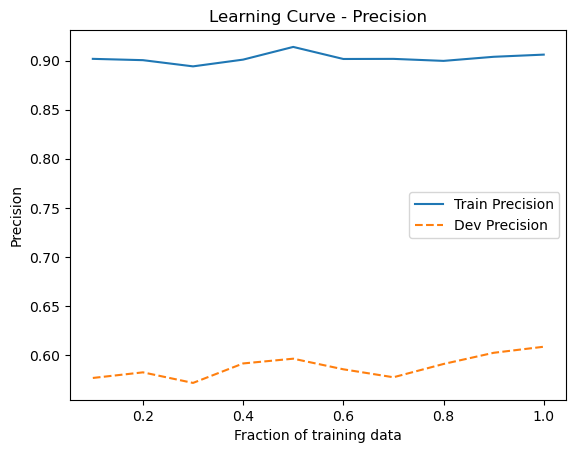

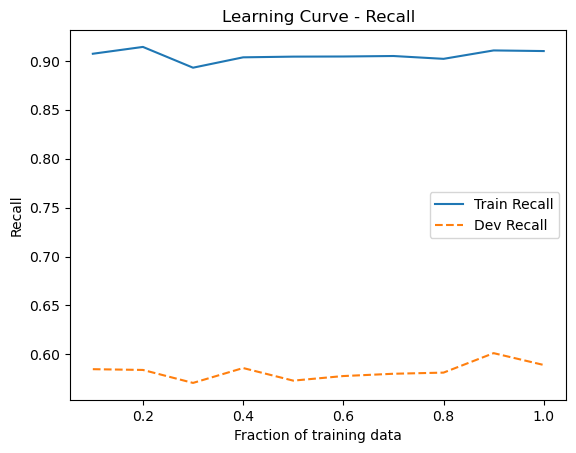

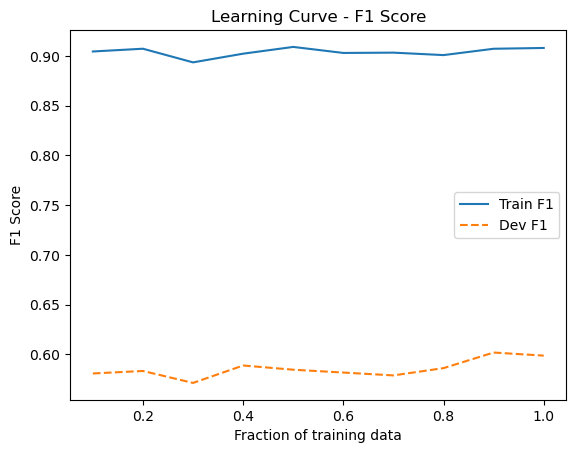

In [8]:
def plot_learning_curves(model, x_train, y_train, x_dev, y_dev, class_label):
    train_sizes = np.linspace(0.1, 1.0, 10)
    precision_vals, recall_vals, f1_vals = [], [], []
    dev_precision_vals, dev_recall_vals, dev_f1_vals = [], [], []

    for frac in train_sizes:
        subset_size = int(frac * len(y_train))
        x_subset, y_subset = x_train[:subset_size], y_train[:subset_size]

        model.fit(x_subset, y_subset)

        # Predictions on training subset
        y_pred_train = model.predict(x_subset)
        precision, recall, f1, _ = precision_recall_fscore_support(y_subset, y_pred_train, average=None)
        precision_vals.append(precision[class_label])
        recall_vals.append(recall[class_label])
        f1_vals.append(f1[class_label])

        # Predictions on development set
        y_pred_dev = model.predict(x_dev)
        dev_precision, dev_recall, dev_f1, _ = precision_recall_fscore_support(y_dev, y_pred_dev, average=None)
        dev_precision_vals.append(dev_precision[class_label])
        dev_recall_vals.append(dev_recall[class_label])
        dev_f1_vals.append(dev_f1[class_label])

    # Plotting Precision
    plt.figure()
    plt.plot(train_sizes, precision_vals, label="Train Precision")
    plt.plot(train_sizes, dev_precision_vals, label="Dev Precision", linestyle="--")
    plt.xlabel("Fraction of training data")
    plt.ylabel("Precision")
    plt.title("Learning Curve - Precision")
    plt.legend()
    plt.show()

    # Plotting Recall
    plt.figure()
    plt.plot(train_sizes, recall_vals, label="Train Recall")
    plt.plot(train_sizes, dev_recall_vals, label="Dev Recall", linestyle="--")
    plt.xlabel("Fraction of training data")
    plt.ylabel("Recall")
    plt.title("Learning Curve - Recall")
    plt.legend()
    plt.show()

    # Plotting F1 Score
    plt.figure()
    plt.plot(train_sizes, f1_vals, label="Train F1")
    plt.plot(train_sizes, dev_f1_vals, label="Dev F1", linestyle="--")
    plt.xlabel("Fraction of training data")
    plt.ylabel("F1 Score")
    plt.title("Learning Curve - F1 Score")
    plt.legend()
    plt.show()
    
# Split training data for learning curve evaluation
x_train_subset, x_dev, y_train_subset, y_dev = train_test_split(x_train_binary, y_train, test_size=0.2, random_state=42)

# Plot learning curves for class 1 (positive reviews)
plot_learning_curves(rf, x_train_subset, y_train_subset, x_dev, y_dev, class_label=1)

## Part B

## Comparing with Scikit-learn Implementations

In [9]:
# Importing Libraries
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

## Random Forest against Scikit-learn Bernoulli Naive Bayes

In [10]:
# Scikit-learn Bernoulli Naive Bayes
bnb = BernoulliNB()
bnb.fit(x_train_binary, y_train)

# Evaluate on test data
y_pred_test_sklearn = bnb.predict(x_test_binary)

# Display results
print("Scikit-learn Bernoulli Naive Bayes - Test set evaluation:")
print(classification_report(y_test, y_pred_test_sklearn))

Scikit-learn Bernoulli Naive Bayes - Test set evaluation:
              precision    recall  f1-score   support

           0       0.82      0.76      0.79     12500
           1       0.77      0.83      0.80     12500

    accuracy                           0.79     25000
   macro avg       0.80      0.79      0.79     25000
weighted avg       0.80      0.79      0.79     25000



## Random Forest against Scikit-learn Random Forest Classifier

In [11]:
# Random Forest Classifier
#rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_sklearn = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=5, random_state=42)

rf_sklearn.fit(x_train_binary, y_train)

# Evaluate on test data
y_pred_test_rf = rf_sklearn.predict(x_test_binary)

# Display results
print("Random Forest Classifier - Test set evaluation:")
print(classification_report(y_test, y_pred_test_rf))

Random Forest Classifier - Test set evaluation:
              precision    recall  f1-score   support

           0       0.83      0.68      0.75     12500
           1       0.73      0.86      0.79     12500

    accuracy                           0.77     25000
   macro avg       0.78      0.77      0.77     25000
weighted avg       0.78      0.77      0.77     25000



## Random Forest against Scikit-learn Logistic Regression

In [12]:
# Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(x_train_binary, y_train)

# Evaluate on test data
y_pred_test_log_reg = log_reg.predict(x_test_binary)

# Display results
print("Logistic Regression - Test set evaluation:")
print(classification_report(y_test, y_pred_test_log_reg))

Logistic Regression - Test set evaluation:
              precision    recall  f1-score   support

           0       0.84      0.82      0.83     12500
           1       0.82      0.84      0.83     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



## Summary of Results

In [13]:
# Summary Table of Results
models = ["Random Forest", "Scikit-learn Bernoulli NB", "Scikit-learn Random Forest", "Scikit-learn Logistic Regression"]
results = [
    classification_report(y_test, y_pred_test, output_dict=True),
    classification_report(y_test, y_pred_test_sklearn, output_dict=True),
    classification_report(y_test, y_pred_test_rf, output_dict=True),
    classification_report(y_test, y_pred_test_log_reg, output_dict=True)
]

for model, result in zip(models, results):
    print("\nModel:", model)
    print("Accuracy:", result['accuracy'])
    print("Precision (weighted avg):", result['weighted avg']['precision'])
    print("Recall (weighted avg):", result['weighted avg']['recall'])
    print("F1-Score (weighted avg):", result['weighted avg']['f1-score'])


Model: Random Forest
Accuracy: 0.58244
Precision (weighted avg): 0.5825080558127437
Recall (weighted avg): 0.58244
F1-Score (weighted avg): 0.5823538773601088

Model: Scikit-learn Bernoulli NB
Accuracy: 0.79444
Precision (weighted avg): 0.7962497856746897
Recall (weighted avg): 0.79444
F1-Score (weighted avg): 0.7941255790317242

Model: Scikit-learn Random Forest
Accuracy: 0.77232
Precision (weighted avg): 0.7815731813264318
Recall (weighted avg): 0.77232
F1-Score (weighted avg): 0.7704339751625113

Model: Scikit-learn Logistic Regression
Accuracy: 0.82748
Precision (weighted avg): 0.8276828403968386
Recall (weighted avg): 0.82748
F1-Score (weighted avg): 0.8274532977766628


## Learning Curves: Precision, Recall, and F1

Scikit-learn Bernoulli Naive Bayes

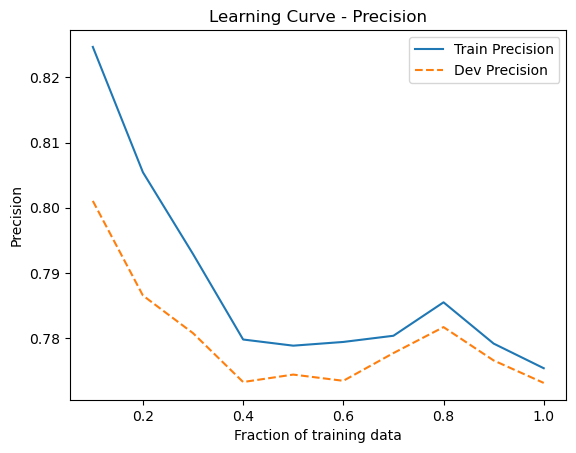

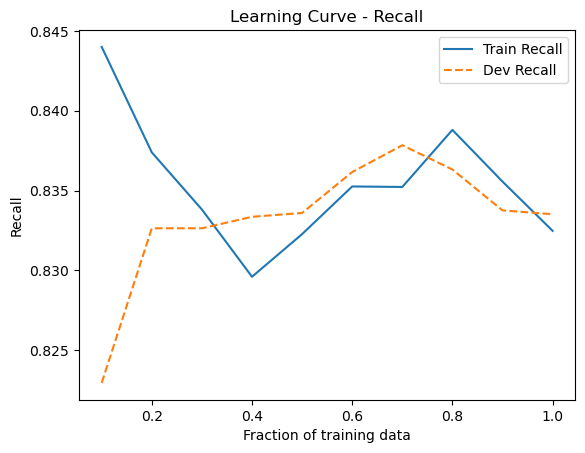

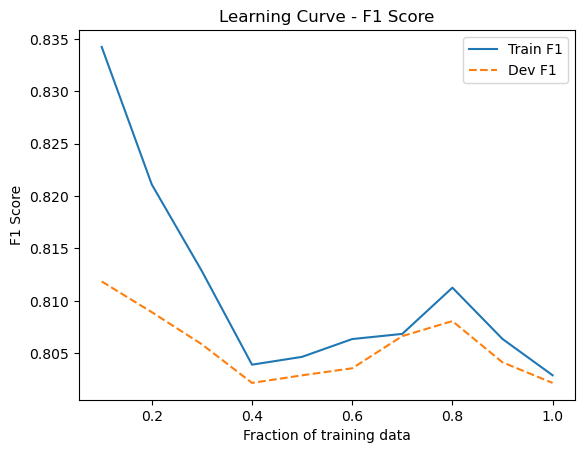

In [14]:
plot_learning_curves(bnb, x_train_binary, y_train, x_test_binary, y_test, class_label=1)

Scikit-learn Random Forest

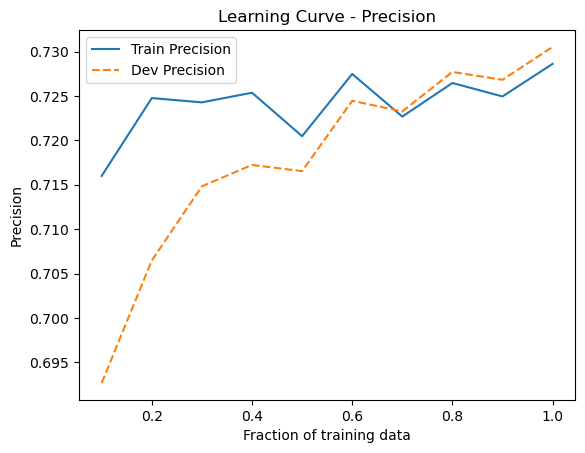

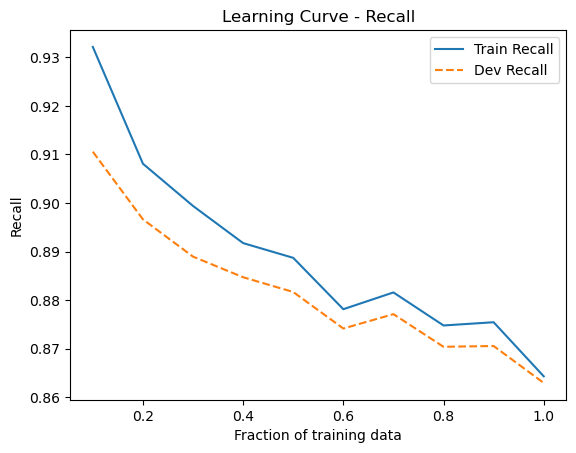

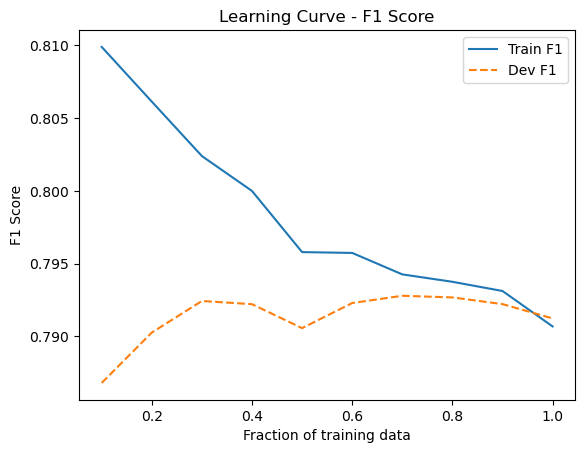

In [15]:
plot_learning_curves(rf_sklearn, x_train_binary, y_train, x_test_binary, y_test, class_label=1)

Scikit-learn Logistic Regression

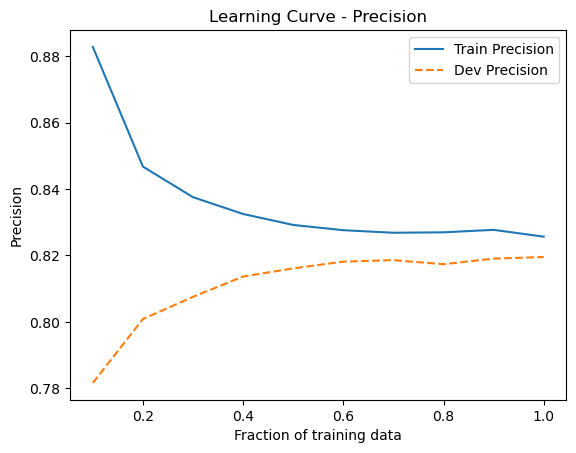

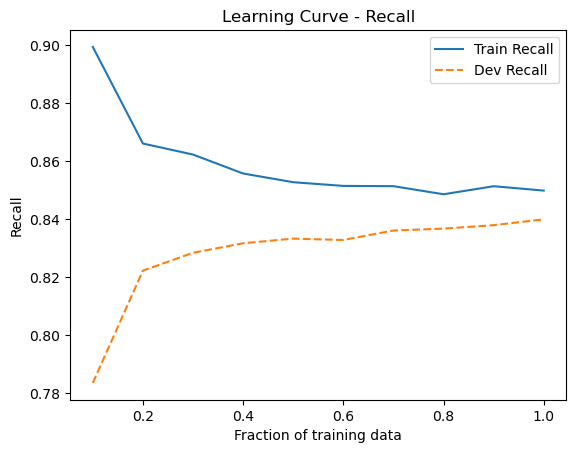

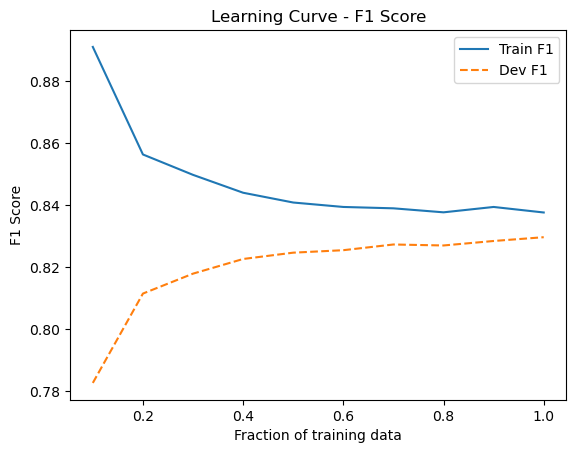

In [16]:
plot_learning_curves(log_reg, x_train_binary, y_train, x_test_binary, y_test, class_label=1)